<a href="https://colab.research.google.com/github/AnisaIntania/Natural-Language-Processing/blob/main/NLP_P5_05_BERT_CONLL_NER_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q --upgrade pip
%pip install -q transformers accelerate seqeval

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Installing required packages
try:
    from google.colab import files
    print("Using Google Colab")
except ModuleNotFoundError:
    print("Not Using Colab")

%pip install -q -U transformers accelerate seqeval scikit-learn

# Importing packages for data processing
import string
import pandas as pd
import numpy as np
import torch
import warnings

from tqdm import tqdm, trange
from sklearn.model_selection import train_test_split

# Importing PyTorch and BERT packages
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    Trainer,
    TrainingArguments
)

# Importing metrics
from seqeval.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report
)

warnings.filterwarnings("ignore")

print("All packages imported successfully!")

Using Google Colab
All packages imported successfully!


In [3]:
#uploading data into google colab
#upload the test.txt and train.txt files respectively
try :
    from google.colab import files
    uploaded = files.upload()

except ModuleNotFoundError :
    print("Not using Colab")

Saving eng.test.txt to eng.test.txt
Saving eng.train.txt to eng.train.txt


In [11]:
def load__data_conll(path):
    sentences = []
    labels = []
    words = []
    tags = []

    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line or line.startswith("-DOCSTART-"):
                if words:
                    sentences.append(words)
                    labels.append(tags)
                    words = []
                    tags = []
                continue

            parts = line.split()
            if len(parts) >= 4:
                words.append(parts[0])
                tags.append(parts[-1])

    if words:
        sentences.append(words)
        labels.append(tags)

    return list(zip(sentences, labels))


conll_train = load__data_conll(train_path)
conll_test = load__data_conll(test_path)

print("Train shape:", len(conll_train), 2)
print("Test shape:", len(conll_test), 2)

Train shape: 14041 2
Test shape: 3250 2


In [12]:
#preprocess the data by calling the functions
try :
    from google.colab import files
    train_path = 'eng.train.txt'
    test_path = 'eng.test.txt'

except ModuleNotFoundError :
    train_path = 'Data/conlldata/eng.train.txt'
    test_path = 'Data/conlldata/eng.test.txt'


conll_train = load__data_conll(train_path)
conll_test = load__data_conll(test_path)

In [9]:
import numpy as np

conll_train = [
    [sentence, label]
    for sentence, label in zip(train_sentences, train_labels)
]

print("Jumlah data:", len(conll_train))
print("Shape:", np.array(conll_train, dtype=object).shape)

Jumlah data: 14041
Shape: (14041, 2)


In [13]:
# Membuat data test per kalimat
conll_test = [
    [sentence, label]
    for sentence, label in zip(test_sentences, test_labels)
]

# Menghitung ukuran data
print(np.array(conll_test, dtype=object).shape)

(3250, 2)


In [15]:
import pandas as pd

def read_conll_dataframe(path):
    rows = []

    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line or line.startswith("-DOCSTART-"):
                continue

            parts = line.split()
            if len(parts) >= 4:
                rows.append(parts[:4])

    return pd.DataFrame(
        rows,
        columns=["Word", "POS", "Chunk", "Tag"]
    )

df_train = read_conll_dataframe(train_path)
df_test = read_conll_dataframe(test_path)

print("Train columns:", df_train.columns.tolist())
print("Test columns:", df_test.columns.tolist())

Train columns: ['Word', 'POS', 'Chunk', 'Tag']
Test columns: ['Word', 'POS', 'Chunk', 'Tag']


In [16]:
# Check dataset columns
print("Train columns:", df_train.columns.tolist())
print("Test columns:", df_test.columns.tolist())

# Gabungkan hanya untuk mengambil daftar label
df = pd.concat([df_train, df_test], ignore_index=True)

# Ambil label dari kolom terakhir
label = df.iloc[:, -1].dropna().astype(str).tolist()

# Ambil semua label unik
unique_labels = sorted(set(label))

print("Unique labels:", unique_labels)

Train columns: ['Word', 'POS', 'Chunk', 'Tag']
Test columns: ['Word', 'POS', 'Chunk', 'Tag']
Unique labels: ['B-LOC', 'B-MISC', 'B-ORG', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']


In [17]:
np.array(conll_train, dtype=object).shape

(14041, 2)

In [18]:
np.array(conll_test, dtype=object).shape

(3250, 2)

In [19]:
import re
def untokenize(words):
    """
    Untokenizing a text undoes the tokenizing operation, restoring
    punctuation and spaces to the places that people expect them to be.
    Ideally, `untokenize(tokenize(text))` should be identical to `text`,
    except for line breaks.
    """
    text = ' '.join(words)
    step1 = text.replace("`` ", '"').replace(" ''", '"').replace('. . .',  '...')
    step2 = step1.replace(" ( ", " (").replace(" ) ", ") ")
    step3 = re.sub(r' ([.,:;?!%]+)([ \'"`])', r"\1\2", step2)
    step4 = re.sub(r' ([.,:;?!%]+)$', r"\1", step3)
    step5 = step4.replace(" '", "'").replace(" n't", "n't").replace(
         "can not", "cannot")
    step6 = step5.replace(" ` ", " '")
    return step6.strip()

In [20]:
#lets convert them to dataframs for easier handling
df_train = pd.DataFrame(conll_train,columns=["sentence","labels"])
df_test = pd.DataFrame(conll_test,columns=["sentence","labels"])

In [21]:
#getting all the sentences and labels present in both test and train
sentences = list(df_train['sentence'])+list(df_test['sentence'])
print("No of sentences:",len(sentences))
labels = list(df_train['labels'])+list(df_test['labels'])
print("No of labels:",len(labels))

No of sentences: 17291
No of labels: 17291


In [22]:
sentences = [untokenize(sent) for sent in sentences]
sentences[0]

'EU rejects German call to boycott British lamb.'

In [23]:
from transformers import BertTokenizer
import torch
#setting up pytorch to use GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpu = torch.cuda.device_count()

#prescribed configurations that we need to fix for BERT.
MAX_LEN = 75
bs = 32

#BERT's implementation comes with a pretained tokenizer and a defined vocabulary
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased', do_lower_case=True)

#tokenizing the text
tokenized_texts = list(map(lambda x: ['[CLS]'] + tokenizer.tokenize(x) + ['[SEP]'] , sentences))
print(tokenized_texts[0])

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

['[CLS]', 'eu', 'rejects', 'german', 'call', 'to', 'boycott', 'british', 'lamb', '.', '[SEP]']


In [24]:
labels[0]

['I-ORG', 'O', 'I-MISC', 'O', 'O', 'O', 'I-MISC', 'O', 'O']

In [25]:
#pre-processing the labels
#converting tags to indices
tags_vals = list(set(label))
tag2idx = {t: i for i, t in enumerate(tags_vals)}

In [26]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
#We now need to give BERT input ids,ie, a sequence of integers which uniquely identify each input token to its index number.
#cutting and padding the tokens and labels to our desired length

input_ids = pad_sequences([tokenizer.convert_tokens_to_ids(txt) for txt in tokenized_texts],
                          maxlen=MAX_LEN, dtype="long", truncating="post", padding="post")

tags = pad_sequences([[tag2idx.get(l) for l in lab] for lab in labels],
                     maxlen=MAX_LEN, value=tag2idx["O"], padding="post",
                     dtype="long", truncating="post")

In [27]:
#BERT supports something called attention masks
#Tells the model which tokens should be attended to, and which should not.
#learn more about this at https://huggingface.co/transformers/glossary.html#attention-mask

attention_masks = [[float(i>0) for i in ii] for ii in input_ids]

In [28]:
#split the dataset to use 20% to validate the model.
tr_inputs, val_inputs, tr_tags, val_tags = train_test_split(input_ids, tags,
                                                            random_state=2020, test_size=0.2)
tr_masks, val_masks, _, _ = train_test_split(attention_masks, input_ids,
                                             random_state=2020, test_size=0.2)

In [29]:
#pytorch requires inputs to be in the form of torch tensors
#Learn more about torch tensors at https://pytorch.org/docs/stable/tensors.html
tr_inputs = torch.tensor(tr_inputs)
val_inputs = torch.tensor(val_inputs)
tr_tags = torch.tensor(tr_tags)
val_tags = torch.tensor(val_tags)
tr_masks = torch.tensor(tr_masks)
val_masks = torch.tensor(val_masks)

In [30]:
#Define the Data Loaders
#Shuffle the data at training time
#Pass them sequentially during test time
from torch.utils.data import TensorDataset, RandomSampler, SequentialSampler, DataLoader
train_data = TensorDataset(tr_inputs, tr_masks, tr_tags)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=bs)
print("Train Data Loaders Ready")
valid_data = TensorDataset(val_inputs, val_masks, val_tags)
valid_sampler = SequentialSampler(valid_data)
valid_dataloader = DataLoader(valid_data, sampler=valid_sampler, batch_size=bs)
print("Test Data Loaders Ready")

Train Data Loaders Ready
Test Data Loaders Ready


In [31]:
# BertForTokenClassification class of pytorch-pretrained-bert package provides  for token-level predictions
from transformers import BertForTokenClassification
model = BertForTokenClassification.from_pretrained("bert-base-uncased", num_labels=len(tag2idx))#loading pre trained bert
print("BERT model ready to use")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly

BERT model ready to use


In [32]:
#Passing model parameters into GPU
if torch.cuda.is_available():
    print("Passing Model parameters in GPU")
    print(model.cuda())
else:
    print(model)

Passing Model parameters in GPU
BertForTokenClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm):

In [33]:
#Before starting fine tuing we need to add the optimizer. Generally Adam is used
#weight_decay is added as regularization to the main weight matrices
from torch.optim import Adam
print("Fine Tuning BERT")
FULL_FINETUNING = True
if FULL_FINETUNING:
    param_optimizer = list(model.named_parameters())
    no_decay = ['bias', 'gamma', 'beta']
    optimizer_grouped_parameters = [
        {'params': [p for n, p in param_optimizer if not any(nd in n for nd in no_decay)],
         'weight_decay_rate': 0.01},
        {'params': [p for n, p in param_optimizer if any(nd in n for nd in no_decay)],
         'weight_decay_rate': 0.0}
    ]
else:
    param_optimizer = list(model.classifier.named_parameters())
    optimizer_grouped_parameters = [{"params": [p for n, p in param_optimizer]}]
optimizer = Adam(optimizer_grouped_parameters, lr=3e-5)

Fine Tuning BERT


In [34]:
#accuracy
def flat_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=2).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)

In [37]:
# Add the epoch number
epochs = 4
max_grad_norm = 1.0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpu = torch.cuda.device_count()
train_loss_set = []

model.to(device)

for _ in trange(epochs, desc="Epoch"):
    # TRAIN loop
    model.train()
    tr_loss = 0
    nb_tr_steps = 0

    for step, batch in enumerate(train_dataloader):
        batch = tuple(t.to(device) for t in batch)
        b_input_ids, b_input_mask, b_labels = batch

        optimizer.zero_grad()

        outputs = model(
            b_input_ids,
            token_type_ids=None,
            attention_mask=b_input_mask,
            labels=b_labels
        )

        loss = outputs.loss
        train_loss_set.append(loss.item())

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=max_grad_norm
        )

        optimizer.step()

        tr_loss += loss.item()
        nb_tr_steps += 1

    print("Train loss: {}".format(tr_loss / max(nb_tr_steps, 1)))

    # VALIDATION
    model.eval()
    eval_loss, eval_accuracy = 0, 0
    nb_eval_steps = 0
    predictions, true_labels = [], []

    for batch in valid_dataloader:
        batch = tuple(t.to(device) for t in batch)
        b_input_ids, b_input_mask, b_labels = batch

        with torch.no_grad():
            outputs = model(
                b_input_ids,
                token_type_ids=None,
                attention_mask=b_input_mask,
                labels=b_labels
            )

        tmp_eval_loss = outputs.loss
        logits = outputs.logits.detach().cpu().numpy()
        label_ids = b_labels.detach().cpu().numpy()

        predictions.extend(np.argmax(logits, axis=2).tolist())
        true_labels.extend(label_ids.tolist())

        eval_loss += tmp_eval_loss.item()
        eval_accuracy += flat_accuracy(logits, label_ids)
        nb_eval_steps += 1

    print("Validation loss: {}".format(
        eval_loss / max(nb_eval_steps, 1)
    ))
    print("Validation Accuracy: {}".format(
        eval_accuracy / max(nb_eval_steps, 1)
    ))

    # F1-score
    pred_tags = []
    valid_tags = []

    for pred_seq, true_seq in zip(predictions, true_labels):
        pred_sentence = []
        true_sentence = []

        for pred_id, true_id in zip(pred_seq, true_seq):
            if true_id != -100 and true_id != tag2idx["O"]:
                pred_sentence.append(tags_vals[pred_id])
                true_sentence.append(tags_vals[true_id])

        if true_sentence:
            pred_tags.append(pred_sentence)
            valid_tags.append(true_sentence)

    print("F1-Score: {}".format(f1_score(pred_tags, valid_tags)))

Epoch:   0%|          | 0/4 [00:00<?, ?it/s]

Train loss: 0.040941075127201874


Epoch:  25%|██▌       | 1/4 [03:18<09:54, 198.09s/it]

Validation loss: 0.03680535531901848
Validation Accuracy: 0.9850496941896021
F1-Score: 0.7389838129496402
Train loss: 0.026361187283319633


Epoch:  50%|█████     | 2/4 [06:46<06:48, 204.33s/it]

Validation loss: 0.027970708176117697
Validation Accuracy: 0.9889462283384293
F1-Score: 0.8004383561643835
Train loss: 0.019764129995146883


Epoch:  75%|███████▌  | 3/4 [10:15<03:26, 206.28s/it]

Validation loss: 0.026609320637829805
Validation Accuracy: 0.9899898063200817
F1-Score: 0.781380065717415
Train loss: 0.01613194465354369


Epoch: 100%|██████████| 4/4 [13:44<00:00, 206.03s/it]

Validation loss: 0.025328086877888956
Validation Accuracy: 0.9913493883792049
F1-Score: 0.8194174757281554


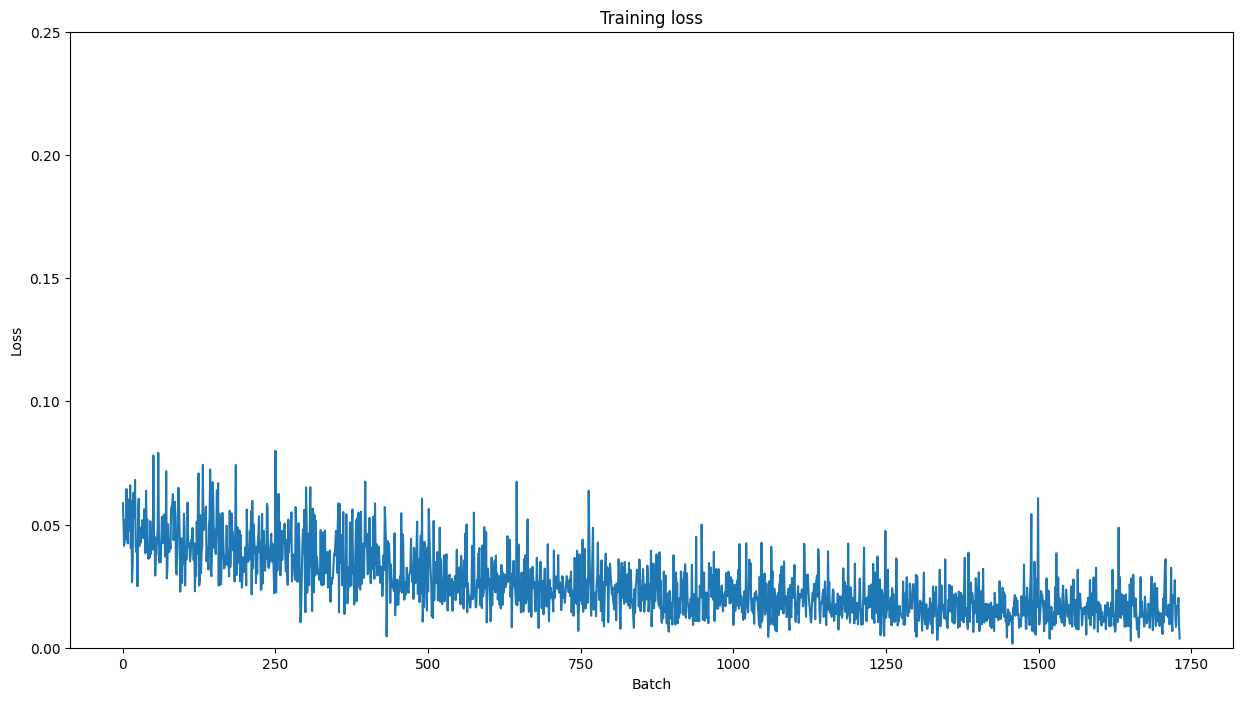

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,8))
plt.title("Training loss")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.ylim(0,0.25)
plt.plot(train_loss_set)
plt.show()

In [40]:
# Evaluate the model
model.eval()
predictions = []
true_labels = []
eval_loss, eval_accuracy = 0, 0
nb_eval_steps, nb_eval_examples = 0, 0

for batch in valid_dataloader:
    batch = tuple(t.to(device) for t in batch)
    b_input_ids, b_input_mask, b_labels = batch

    with torch.no_grad():
        outputs = model(
            b_input_ids,
            token_type_ids=None,
            attention_mask=b_input_mask,
            labels=b_labels
        )

        tmp_eval_loss = outputs.loss
        logits = outputs.logits

    logits = logits.detach().cpu().numpy()
    predictions.extend(np.argmax(logits, axis=2).tolist())

    label_ids = b_labels.detach().cpu().numpy()
    true_labels.extend(label_ids.tolist())

    tmp_eval_accuracy = flat_accuracy(logits, label_ids)

    eval_loss += tmp_eval_loss.item()
    eval_accuracy += tmp_eval_accuracy
    nb_eval_examples += b_input_ids.size(0)
    nb_eval_steps += 1

# Convert predictions and labels
pred_tags = []
valid_tags = []

for pred_seq, true_seq in zip(predictions, true_labels):
    pred_sentence = []
    true_sentence = []

    for pred_id, true_id in zip(pred_seq, true_seq):
        if true_id != -100:
            pred_sentence.append(tags_vals[pred_id])
            true_sentence.append(tags_vals[true_id])

    pred_tags.append(pred_sentence)
    valid_tags.append(true_sentence)

print("Validation loss: {}".format(eval_loss / max(nb_eval_steps, 1)))
print("Validation Accuracy: {}".format(eval_accuracy / max(nb_eval_steps, 1)))
print("Validation F1-Score: {}".format(f1_score(pred_tags, valid_tags)))

Validation loss: 0.025328086877888956
Validation Accuracy: 0.9913493883792049
Validation F1-Score: 0.7649195640892579
